In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import os
import itertools
import warnings
from tqdm import tqdm
from scripts import process
from scripts import analyse
from scripts import scrp_hrh
from scripts import scrp_serv
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.graph_objects as go
import math
from IPython.display import clear_output

pd.set_option('display.max_rows', 300)
pd.set_option('future.no_silent_downcasting', True)
warnings.simplefilter('ignore', DeprecationWarning)

# Set a standardized style of graph
plt.rcParams.update({
    "font.size": 10,  # Standard font size for high-impact journals
    "font.family": "Arial",  # Standard font
    "axes.linewidth": 1,  # Line thickness
    "grid.alpha": 0.6,  # Grid transparency
    "grid.linestyle": "--",  # Grid style
})

/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_36847/3788301701.py:21: Pandas4Warning: 'future.no_silent_downcasting' is deprecated, please refrain from using it.
  pd.set_option('future.no_silent_downcasting', True)


### Popolation Modelling

In [2]:
# Import Thailand population data
pop_file = 'pop'
data_dir = 'data/pop/age'
output_dir = 'output/clean'

years = range(2013,2025)

pop_country = pd.DataFrame()
pop_hregion = pd.DataFrame()
pop_prov = pd.DataFrame()
pop_dist = pd.DataFrame()

id_cols = ['year', 'prov_id', 'prov', 'dist_id', 'dist', 'subdist_id', 'subdist', 'village_id', 'village']

def sum_age_range(pop, lo, hi):
    cols = [f'{sex}_yr{age}' for age in range(lo, hi + 1) for sex in ('m', 'f')]
    return pop[cols].sum(axis=1)

def add_age_bands(df):
    age_bands = pd.DataFrame({
        'newborn': df['m_yr0'] + df['f_yr0'],
        'child': sum_age_range(df, 1, 14),
        'reproductive': sum_age_range(df, 15, 44),
        'pre-ageing': sum_age_range(df, 45, 64),
        'ageing': sum_age_range(df, 65, 101),
    })
    return pd.concat([df, age_bands], axis=1).copy()

for year in years:

    pop_file = f'data/pop/age/pop_{year}.xlsx'
    pop = pd.read_excel(pop_file, sheet_name='pop')
    pop = process.DataCleaning.update_column_name(pop, 'data/pop/age/data_dict-pop.xlsx')
    pop = pop.copy()  # read_excel leaves one block per column; consolidate before adding/aggregating columns
    pop['year'] = year
    pop['dist_id'] = pop['subdist_id'].astype(str).str[:4].astype(int)  # raw dist_id is unreliable; derive from subdist_id instead

    value_cols = [c for c in pop.columns if c not in id_cols]

    # Create population dataset in district level
    dist_yr = pop.groupby(['year', 'prov_id', 'dist_id'], as_index=False)[value_cols].sum()
    dist_yr = add_age_bands(dist_yr)
    pop_dist = pd.concat([pop_dist, dist_yr], ignore_index=True)

    # Create population dataset in provincial level
    prov_yr = pop.groupby(['year', 'prov_id'], as_index=False)[value_cols].sum()
    prov_yr = add_age_bands(prov_yr)
    pop_prov = pd.concat([pop_prov, prov_yr], ignore_index=True)

    # Create population dataset in health regional level (province name is only needed
    # transiently to look up the region, then dropped in favor of hregion_id)
    hregion_yr = pop.groupby(['year', 'prov'], as_index=False)[value_cols].sum()
    hregion_yr['prov'] = hregion_yr['prov'].apply(lambda x: x if x in ['กรุงเทพมหานคร', 'ทั่วประเทศ'] else x[7:])
    hregion_yr = process.DataManipulation.mapping(hregion_yr, 'prov')
    hregion_yr['hregion_id'] = hregion_yr['prov'].apply(lambda x: x[-2:] if len(x) == 15 else x[-1:])
    hregion_yr = hregion_yr.drop(columns='prov').groupby(['year', 'hregion_id'], as_index=False)[value_cols].sum()
    hregion_yr = add_age_bands(hregion_yr)
    pop_hregion = pd.concat([pop_hregion, hregion_yr], ignore_index=True)

    # Create population dataset in country level
    country_yr = pop.groupby('year', as_index=False)[value_cols].sum()
    country_yr = add_age_bands(country_yr)
    pop_country = pd.concat([pop_country, country_yr], ignore_index=True)

pop_dist.to_csv('output/clean/pop_age/pop_dist.csv', index=False)
pop_prov.to_csv('output/clean/pop_age/pop_prov.csv', index=False)
pop_hregion.to_csv('output/clean/pop_age/pop_hregion.csv', index=False)
pop_country.to_csv('output/clean/pop_age/pop_country.csv', index=False)

clear_output()
display(pop_dist.head())

,year,prov_id,dist_id,m_yr0,f_yr0,m_yr1,f_yr1,m_yr2,f_yr2,m_yr3,...,f_move,total_move,pop_male,pop_female,pop,newborn,child,reproductive,pre-ageing,ageing
0,2013,10,1001,150,123,177,141,160,148,144,...,30,160,27279,29405,56684,273,7899,22756,16197,7541
1,2013,10,1002,332,316,419,334,399,337,388,...,436,2243,57158,49653,106811,648,11732,44929,28596,13979
2,2013,10,1003,1051,1016,1152,1079,1153,1082,1130,...,70,179,77988,81974,159962,2067,33298,77529,36706,9475
3,2013,10,1004,124,110,146,119,148,117,138,...,492,1037,21792,24322,46114,234,4419,16625,12108,5840
4,2013,10,1005,828,734,942,893,986,889,984,...,171,919,91208,99336,190544,1562,27804,88439,53583,16166


In [3]:
# Build the population model

In [4]:
# --- Cohort-component population projection, district level ---
# Method: Hamilton-Perry model (Hamilton & Perry, 1962) -- a reduced-form
# cohort-component projection that ages each single-year cohort forward using
# a Cohort Change Ratio (CCR) implied by comparing consecutive years' age
# distributions, rather than separately modelled mortality/fertility/migration
# rates. Because we only observe population stocks, the CCR bundles survival
# and net migration together. District-level CCRs are noisy for small
# districts (see earlier prototype), so each (district, sex, age) CCR falls
# back to its province-level equivalent whenever the district's historical
# source cohort was too small to trust -- the same rationale as Inoue (2017)
# smoothing small-area CCRs against the encompassing region.
#
# Following Wilson & Grossman (2022, Spatial Demography), who evaluate several
# Hamilton-Perry implementations for Australian small areas, this notebook
# also implements: (1) a Cohort Change Ratio / Cohort Change Difference (CCD)
# hybrid, which uses the additive CCD for growing cohorts to avoid runaway
# compounding of a ratio >1 over a long horizon; (2) a No Change benchmark;
# (3) MedAPE/Median PE as the primary (outlier-robust) accuracy and bias
# metrics; (4) constraining district totals to an independent province-level
# projection; and (5) the Index of Dissimilarity to score age-sex structure
# accuracy, not just total population.

pop_dist = pd.read_csv('output/clean/pop_age/pop_dist.csv')
pop_prov = pd.read_csv('output/clean/pop_age/pop_prov.csv')
pop_dist = pop_dist[pop_dist['pop'] > 0].copy()  # drop a handful of zero-pop artifact rows

MAX_SINGLE_AGE = 99  # ages 0..99 kept as single years; 100 & 101 merged into an open '100+' group

def add_100plus(df):
    df = df.copy()
    for sex in ('m', 'f'):
        df[f'{sex}_yr100p'] = df[f'{sex}_yr100'] + df[f'{sex}_yr101']
    return df

pop_dist = add_100plus(pop_dist)
pop_prov = add_100plus(pop_prov)

def state_col(sex, age):
    return f'{sex}_yr{age}'

In [5]:
def cohort_rates(df, id_col):
    """
    For each group (district or province), estimate the Cohort Change Ratio
    (CCR) and Cohort Change Difference (CCD) of Hamilton & Perry (1962):
      - ccr[gid][sex]: array of 100 ratios P(a,t+1)/P(a-1,t). Index a-1 (a=1..99)
        feeds cohort age a from age a-1 the previous year; index 99 feeds the
        open '100+' group from the pooled (age 99 + existing 100+) cohort.
      - ccd[gid][sex]: the equivalent additive difference P(a,t+1)-P(a-1,t) for
        the same cohorts. Wilson & Grossman (2022) use CCD instead of CCR for
        growing cohorts to prevent a ratio >1 compounding into runaway growth
        over a long horizon.
      - src_size[gid][sex]: average historical size of the source cohort behind
        each ratio (used later to decide whether to trust the district's own
        rate or fall back to its province -- CCD is scale-dependent so it must
        NEVER be borrowed across geographic levels, only CCR can be).
      - birth_rate[gid]: mean(total births in year t+1 / reproductive women in
        year t) -- our estimate of the Child/Woman Ratio (CWR) used to project
        the newborn cohort.
      - birth_sex_ratio[gid]: mean male share of births
      - repro_size[gid]: average reproductive-women count (trust threshold for births)
    """
    ccr, ccd, src_sizes, birth_rate, birth_sex_ratio, repro_size = {}, {}, {}, {}, {}, {}

    for gid, g in df.sort_values('year').groupby(id_col):
        g = g.set_index('year')
        yrs = g.index.tolist()

        age_samples = {sex: [[] for _ in range(100)] for sex in ('m', 'f')}
        birth_rate_samples, birth_sexratio_samples, repro_samples = [], [], []

        for i in range(len(yrs) - 1):
            t, t1 = yrs[i], yrs[i + 1]
            if t1 - t != 1:
                continue

            for sex in ('m', 'f'):
                for a in range(1, MAX_SINGLE_AGE + 1):
                    src = g.loc[t, state_col(sex, a - 1)]
                    tgt = g.loc[t1, state_col(sex, a)]
                    if src > 0:
                        age_samples[sex][a - 1].append((tgt / src, tgt - src, src))
                src100 = g.loc[t, state_col(sex, MAX_SINGLE_AGE)] + g.loc[t, f'{sex}_yr100p']
                tgt100 = g.loc[t1, f'{sex}_yr100p']
                if src100 > 0:
                    age_samples[sex][99].append((tgt100 / src100, tgt100 - src100, src100))

            births_t1 = g.loc[t1, 'm_yr0'] + g.loc[t1, 'f_yr0']
            repro_women_t = g.loc[t, [f'f_yr{a}' for a in range(15, 45)]].sum()
            repro_samples.append(repro_women_t)
            if repro_women_t > 0:
                birth_rate_samples.append(births_t1 / repro_women_t)
            if births_t1 > 0:
                birth_sexratio_samples.append(g.loc[t1, 'm_yr0'] / births_t1)

        r, d, n = {}, {}, {}
        for sex in ('m', 'f'):
            rvals, dvals, sizes = np.full(100, np.nan), np.full(100, np.nan), np.zeros(100)
            for a in range(100):
                samples = age_samples[sex][a]
                if samples:
                    ratio_vals, diff_vals, size_vals = zip(*samples)
                    rvals[a] = np.mean(ratio_vals)
                    dvals[a] = np.mean(diff_vals)
                    sizes[a] = np.mean(size_vals)
            r[sex], d[sex], n[sex] = rvals, dvals, sizes

        ccr[gid] = r
        ccd[gid] = d
        src_sizes[gid] = n
        birth_rate[gid] = np.mean(birth_rate_samples) if birth_rate_samples else np.nan
        birth_sex_ratio[gid] = np.mean(birth_sexratio_samples) if birth_sexratio_samples else 0.514  # Thailand long-run avg male share at birth
        repro_size[gid] = np.mean(repro_samples) if repro_samples else 0

    return ccr, ccd, src_sizes, birth_rate, birth_sex_ratio, repro_size

prov_ccr, prov_ccd, prov_src, prov_birth_rate, prov_birth_sexratio, prov_repro = cohort_rates(pop_prov, 'prov_id')
dist_ccr, dist_ccd, dist_src, dist_birth_rate, dist_birth_sexratio, dist_repro = cohort_rates(pop_dist, 'dist_id')

In [6]:
# Hybrid rates: trust a district's own CCR/birth-rate only where its historical
# source cohort was large enough; otherwise borrow the province-level estimate.
#
# IMPORTANT: CCR is a ratio, so it is scale-invariant and safe to borrow across
# geography levels. CCD is an absolute head-count difference, so it is NOT
# scale-invariant -- borrowing a province's CCD (e.g. "+20,000/year") onto a
# small district would be nonsense. So CCD is only ever used where the
# district itself has enough local data to estimate its own; whenever a
# district falls back to its province, it always uses that province's CCR,
# even for a growing cohort. (Confirmed empirically: naively borrowing province
# CCD blew up one small district's 5-year backtest projection ~20x.)
TRUST_THRESHOLD = 100  # min avg historical source-cohort size to trust a district-level rate

dist_prov_map = pop_dist[['dist_id', 'prov_id']].drop_duplicates().set_index('dist_id')['prov_id']

def build_hybrid_rates(dist_ccr, dist_ccd, dist_src, dist_repro, dist_birth_rate, dist_birth_sexratio,
                        prov_ccr, prov_birth_rate, prov_birth_sexratio, dist_prov_map, trust_threshold):
    hybrid_ccr, hybrid_ccd, hybrid_trust_local, hybrid_birth_rate, hybrid_birth_sexratio = {}, {}, {}, {}, {}

    for did, prov_id in dist_prov_map.items():
        if did not in dist_ccr or prov_id not in prov_ccr:
            continue
        r, d, trust_local = {}, {}, {}
        for sex in ('m', 'f'):
            d_r, d_d, d_n = dist_ccr[did][sex], dist_ccd[did][sex], dist_src[did][sex]
            p_r = prov_ccr[prov_id][sex]
            use_dist = (d_n >= trust_threshold) & ~np.isnan(d_r)
            r[sex] = np.where(use_dist, d_r, p_r)
            r[sex] = np.where(np.isnan(r[sex]), 1.0, r[sex])  # no data anywhere: assume flat retention
            d[sex] = np.where(use_dist, d_d, 0.0)              # CCD only trusted from the district itself
            d[sex] = np.where(np.isnan(d[sex]), 0.0, d[sex])
            trust_local[sex] = use_dist
        hybrid_ccr[did], hybrid_ccd[did], hybrid_trust_local[did] = r, d, trust_local

        use_dist_birth = (dist_repro[did] >= trust_threshold) and not np.isnan(dist_birth_rate[did])
        hybrid_birth_rate[did] = dist_birth_rate[did] if use_dist_birth else prov_birth_rate[prov_id]
        hybrid_birth_sexratio[did] = dist_birth_sexratio[did] if use_dist_birth else prov_birth_sexratio[prov_id]

    return hybrid_ccr, hybrid_ccd, hybrid_trust_local, hybrid_birth_rate, hybrid_birth_sexratio

hybrid_ccr, hybrid_ccd, hybrid_trust_local, hybrid_birth_rate, hybrid_birth_sexratio = build_hybrid_rates(
    dist_ccr, dist_ccd, dist_src, dist_repro, dist_birth_rate, dist_birth_sexratio,
    prov_ccr, prov_birth_rate, prov_birth_sexratio, dist_prov_map, TRUST_THRESHOLD
)

n_district_trusted = sum(hybrid_trust_local[did][sex].sum() for did in hybrid_trust_local for sex in ('m', 'f'))
n_total_cells = len(hybrid_trust_local) * 100 * 2
print(f'District-level CCR trusted for {n_district_trusted}/{n_total_cells} (district, sex, age) cells ({n_district_trusted / n_total_cells:.1%})')

District-level CCR trusted for 139484/185600 (district, sex, age) cells (75.2%)


In [7]:
# Project each district forward from the latest actual year using the hybrid rates.
# Hamilton-Perry CCR/CCD rule (Wilson & Grossman, 2022, eq. 5-6): a cohort with
# CCR < 1.0 (declining) is projected multiplicatively with its CCR; a cohort
# with CCR >= 1.0 (growing) is projected additively with its CCD instead, so a
# ratio slightly above 1 can't compound into implausible growth over a 30-year
# horizon. CCD is only applied where it's locally trusted (see previous cell);
# otherwise even a "growing" cohort still uses the (borrowed) CCR.
LAST_YEAR = pop_dist['year'].max()
HORIZON = 30

state_cols = {
    sex: [state_col(sex, a) for a in range(MAX_SINGLE_AGE + 1)] + [f'{sex}_yr100p']
    for sex in ('m', 'f')
}
base = pop_dist[pop_dist['year'] == LAST_YEAR].set_index('dist_id')

current = {
    did: {sex: base.loc[did, state_cols[sex]].to_numpy(dtype=float) for sex in ('m', 'f')}
    for did in hybrid_ccr
}

records = []
for did, vecs in current.items():
    records.append({'dist_id': did, 'year': LAST_YEAR, **{f'{sex}_yr{a}': vecs[sex][a] for sex in ('m', 'f') for a in range(100)},
                     **{f'{sex}_yr100p': vecs[sex][100] for sex in ('m', 'f')}})

for step in range(1, HORIZON + 1):
    year = LAST_YEAR + step
    for did, vecs in current.items():
        r, d, trust_local = hybrid_ccr[did], hybrid_ccd[did], hybrid_trust_local[did]
        new_vecs = {}
        for sex in ('m', 'f'):
            v = vecs[sex]
            new_v = np.empty_like(v)
            use_ccd = (r[sex] >= 1.0) & trust_local[sex]  # growing AND locally-trusted only
            new_v[1:100] = np.where(use_ccd[0:99], v[0:99] + d[sex][0:99], v[0:99] * r[sex][0:99])
            new_v[100] = v[99] + d[sex][99] if use_ccd[99] else (v[99] + v[100]) * r[sex][99]
            new_vecs[sex] = np.maximum(new_v, 0)  # CCD is additive and could otherwise push a cohort negative

        repro_women = vecs['f'][15:45].sum()
        births = repro_women * hybrid_birth_rate[did]
        new_vecs['m'][0] = births * hybrid_birth_sexratio[did]
        new_vecs['f'][0] = births * (1 - hybrid_birth_sexratio[did])

        current[did] = new_vecs
        records.append({'dist_id': did, 'year': year, **{f'{sex}_yr{a}': new_vecs[sex][a] for sex in ('m', 'f') for a in range(100)},
                         **{f'{sex}_yr100p': new_vecs[sex][100] for sex in ('m', 'f')}})

pop_dist_proj = pd.DataFrame(records).merge(dist_prov_map.reset_index(), on='dist_id')
pop_dist_proj['pop'] = pop_dist_proj[[c for c in pop_dist_proj.columns if c.startswith(('m_yr', 'f_yr'))]].sum(axis=1)
pop_dist_proj.to_csv('output/clean/pop_age/pop_dist_projected.csv', index=False)

display(pop_dist_proj.groupby('year')['pop'].sum().round(0))

year
2024    64725259.0
2025    64734624.0
2026    64725868.0
2027    64695235.0
2028    64645294.0
2029    64576544.0
2030    64488717.0
2031    64382552.0
2032    64256547.0
2033    64111159.0
2034    63947904.0
2035    63764580.0
2036    63561705.0
2037    63337656.0
2038    63091039.0
2039    62823750.0
2040    62535409.0
2041    62227708.0
2042    61901209.0
2043    61557224.0
2044    61194760.0
2045    60818991.0
2046    60424322.0
2047    60016564.0
2048    59594774.0
2049    59161473.0
2050    58717534.0
2051    58263928.0
2052    57801938.0
2053    57332436.0
2054    56856764.0
Name: pop, dtype: float64

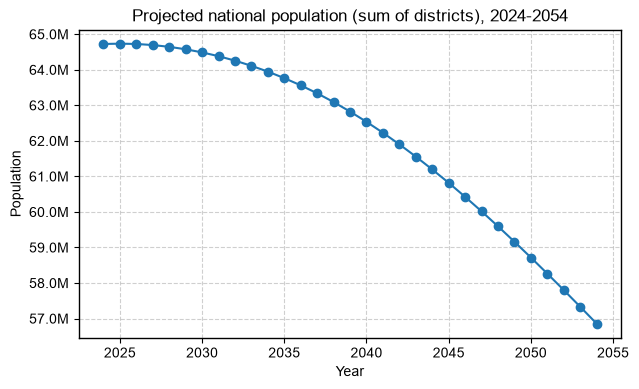

Change 2024-2054: -7,868,495 (-12.2%)


In [8]:
# Sanity check: national total should move gradually, not explode or collapse,
# and should be broadly consistent with Thailand's known low-fertility trajectory.
national = pop_dist_proj.groupby('year')['pop'].sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(national.index, national.values, marker='o')
ax.set_title(f'Projected national population (sum of districts), {min(pop_dist_proj['year'])}-{max(pop_dist_proj['year'])}')
ax.set_xlabel('Year')
ax.set_ylabel('Population')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.grid(True)
plt.show()

print(f"Change {LAST_YEAR}-{LAST_YEAR + HORIZON}: {national.iloc[-1] - national.iloc[0]:+,.0f} "
      f"({(national.iloc[-1] / national.iloc[0] - 1):+.1%})")

In [9]:
# add the modelling back-test to see the error
#
# Out-of-sample check: train the same hybrid Hamilton-Perry CCR/CCD model on
# data up to BACKTEST_TRAIN_END only, project forward to LAST_YEAR, then
# compare the projection against the actual LAST_YEAR data we already have
# (held out of training). This is the only way to see a real error, since
# every year beyond LAST_YEAR is unobserved. A No Change benchmark (population
# frozen at its BACKTEST_TRAIN_END value) is included too, per Wilson &
# Grossman (2022): a Hamilton-Perry model is only worth using if it beats it.

BACKTEST_TRAIN_END = 2019   # last year the model is allowed to see
BACKTEST_HORIZON = LAST_YEAR - BACKTEST_TRAIN_END

def project_district(pop_df, hybrid_ccr, hybrid_ccd, hybrid_trust_local, hybrid_birth_rate, hybrid_birth_sexratio,
                      start_year, horizon):
    """Same CCR/CCD aging/birth mechanics as the main projection loop, but
    returns the full age-sex vector per district (needed for the Index of
    Dissimilarity below), not just the summed total."""
    base = pop_df[pop_df['year'] == start_year].set_index('dist_id')
    current = {
        did: {sex: base.loc[did, state_cols[sex]].to_numpy(dtype=float) for sex in ('m', 'f')}
        for did in hybrid_ccr if did in base.index
    }
    for _ in range(horizon):
        for did, vecs in current.items():
            r, d, trust_local = hybrid_ccr[did], hybrid_ccd[did], hybrid_trust_local[did]
            new_vecs = {}
            for sex in ('m', 'f'):
                v = vecs[sex]
                new_v = np.empty_like(v)
                use_ccd = (r[sex] >= 1.0) & trust_local[sex]
                new_v[1:100] = np.where(use_ccd[0:99], v[0:99] + d[sex][0:99], v[0:99] * r[sex][0:99])
                new_v[100] = v[99] + d[sex][99] if use_ccd[99] else (v[99] + v[100]) * r[sex][99]
                new_vecs[sex] = np.maximum(new_v, 0)
            repro_women = vecs['f'][15:45].sum()
            births = repro_women * hybrid_birth_rate[did]
            new_vecs['m'][0] = births * hybrid_birth_sexratio[did]
            new_vecs['f'][0] = births * (1 - hybrid_birth_sexratio[did])
            current[did] = new_vecs
    return current

# Train on the truncated window only
train_dist = pop_dist[pop_dist['year'] <= BACKTEST_TRAIN_END]
train_prov = pop_prov[pop_prov['year'] <= BACKTEST_TRAIN_END]

bt_prov_ccr, bt_prov_ccd, bt_prov_src, bt_prov_birth_rate, bt_prov_birth_sexratio, bt_prov_repro = cohort_rates(train_prov, 'prov_id')
bt_dist_ccr, bt_dist_ccd, bt_dist_src, bt_dist_birth_rate, bt_dist_birth_sexratio, bt_dist_repro = cohort_rates(train_dist, 'dist_id')

bt_hybrid_ccr, bt_hybrid_ccd, bt_hybrid_trust_local, bt_hybrid_birth_rate, bt_hybrid_birth_sexratio = build_hybrid_rates(
    bt_dist_ccr, bt_dist_ccd, bt_dist_src, bt_dist_repro, bt_dist_birth_rate, bt_dist_birth_sexratio,
    bt_prov_ccr, bt_prov_birth_rate, bt_prov_birth_sexratio, dist_prov_map, TRUST_THRESHOLD
)

predicted_vecs = project_district(train_dist, bt_hybrid_ccr, bt_hybrid_ccd, bt_hybrid_trust_local,
                                   bt_hybrid_birth_rate, bt_hybrid_birth_sexratio, BACKTEST_TRAIN_END, BACKTEST_HORIZON)
predicted = pd.Series({did: v['m'].sum() + v['f'].sum() for did, v in predicted_vecs.items()})

actual = pop_dist[pop_dist['year'] == LAST_YEAR].set_index('dist_id')['pop']
no_change = pop_dist[pop_dist['year'] == BACKTEST_TRAIN_END].set_index('dist_id')['pop']  # No Change benchmark
avg_train_size = train_dist.groupby('dist_id')['pop'].mean()

backtest = pd.DataFrame({
    'predicted': predicted, 'no_change': no_change, 'actual': actual, 'avg_train_size': avg_train_size
}).dropna()
backtest['error'] = backtest['predicted'] - backtest['actual']
backtest['pct_error'] = backtest['error'] / backtest['actual']
backtest['nochange_pct_error'] = (backtest['no_change'] - backtest['actual']) / backtest['actual']

print(f"Backtest: trained on {pop_dist['year'].min()}-{BACKTEST_TRAIN_END}, "
      f"projected {BACKTEST_HORIZON} years forward to {LAST_YEAR}, scored against actual {LAST_YEAR} data.")
display(backtest.head())

Backtest: trained on 2013-2019, projected 5 years forward to 2024, scored against actual 2024 data.


,predicted,no_change,actual,avg_train_size,error,pct_error,nochange_pct_error
1001,39685.506246,47701,39345,52541.714286,340.506246,0.008654,0.212378
1002,70689.412384,89769,74584,98815.142857,-3894.587616,-0.052217,0.203596
1003,187455.841397,176022,186227,167905.714286,1228.841397,0.006599,-0.054799
1004,33742.013302,48227,41701,47274.571429,-7958.986698,-0.190858,0.156495
1005,183170.856387,189000,184231,190502.571429,-1060.143613,-0.005754,0.025886


District-level (n=928):
No Change (benchmark)         MedAPE= 2.25%  MAPE= 2.90%  MedianPE(bias)=+1.63%  90th%APE= 5.70%
Hamilton-Perry CCR/CCD        MedAPE= 0.85%  MAPE= 1.85%  MedianPE(bias)=+0.45%  90th%APE= 2.61%

National total: actual=65,951,210  predicted=65,568,237  error=-0.6%


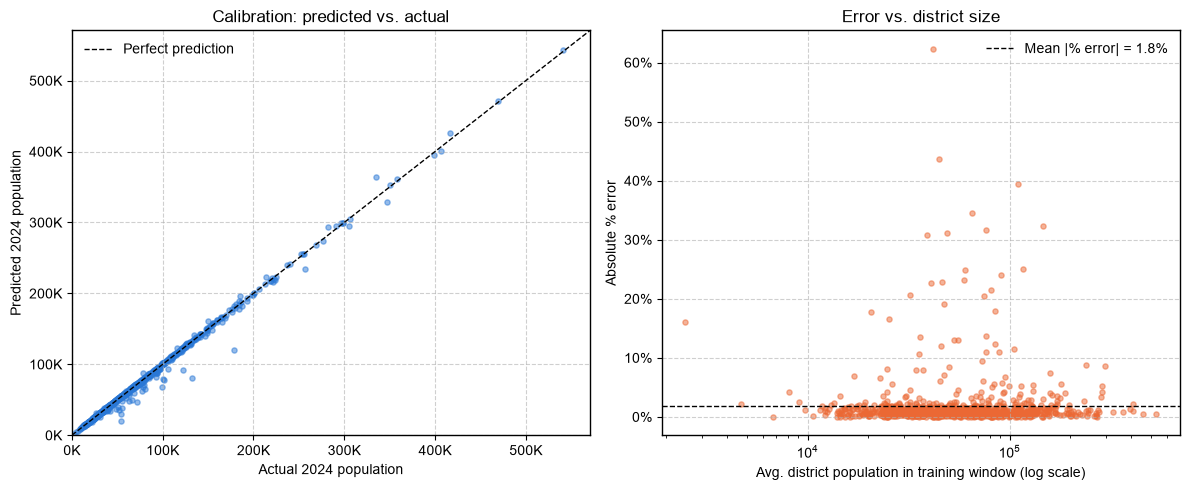


Worst 10 districts by absolute % error:


,predicted,no_change,actual,avg_train_size,error,pct_error,nochange_pct_error
5020,20428.209804,52030,54209,41804.000000,-33780.790196,-0.623158,-0.040196
7108,30664.743223,48694,54459,44739.000000,-23794.256777,-0.436921,-0.105859
5709,80249.749124,124381,132676,110537.428571,-52426.250876,-0.395145,-0.062521
7107,46731.805721,68569,71315,65020.428571,-24583.194279,-0.344713,-0.038505
6306,120778.481383,167178,178467,147155.285714,-57688.518617,-0.323245,-0.063255
6307,67968.481065,87864,99450,76812.857143,-31481.518935,-0.316556,-0.116501
7003,38149.784850,53504,55409,49128.285714,-17259.215150,-0.311488,-0.034381
6308,36166.556977,45562,52206,39193.714286,-16039.443023,-0.307234,-0.127265
5009,91990.897978,120759,122657,117095.428571,-30666.102022,-0.250015,-0.015474
7102,50158.825170,64116,66733,60315.571429,-16574.174830,-0.248365,-0.039216


In [10]:
# Backtest error metrics + diagnostics.
# Following Wilson & Grossman (2022), MedAPE (Median Absolute Percentage Error)
# is the headline accuracy metric -- unlike MAPE it isn't dominated by the
# handful of large-outlier districts we already found (e.g. border provinces).
# Bias is the Median (signed) Percentage Error. MAPE/MAE/RMSE are also kept for
# comparability with the earlier version of this backtest.
def pe(pred, actual):
    return (pred - actual) / actual * 100

def report_metrics(pred, actual, label):
    p = pe(pred, actual)
    print(f"{label:28s}  MedAPE={p.abs().median():5.2f}%  MAPE={p.abs().mean():5.2f}%  "
          f"MedianPE(bias)={p.median():+5.2f}%  90th%APE={p.abs().quantile(.9):5.2f}%")

print(f"District-level (n={len(backtest)}):")
report_metrics(backtest['no_change'], backtest['actual'], 'No Change (benchmark)')
report_metrics(backtest['predicted'], backtest['actual'], 'Hamilton-Perry CCR/CCD')

national_actual = backtest['actual'].sum()
national_predicted = backtest['predicted'].sum()
print(f"\nNational total: actual={national_actual:,.0f}  predicted={national_predicted:,.0f}  "
      f"error={national_predicted / national_actual - 1:+.1%}")

mape = backtest['pct_error'].abs().mean()  # kept for the reference line in the right-hand plot below
series1, series2 = '#2a78d6', '#eb6834'  # validated categorical slots 1 & 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Calibration: predicted vs actual, districts on the 45-degree line are spot on
ax = axes[0]
ax.scatter(backtest['actual'], backtest['predicted'], s=14, alpha=0.5, color=series1)
lims = [0, max(backtest['actual'].max(), backtest['predicted'].max()) * 1.05]
ax.plot(lims, lims, color='black', linewidth=1, linestyle='--', label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(f'Actual {LAST_YEAR} population')
ax.set_ylabel(f'Predicted {LAST_YEAR} population')
ax.set_title('Calibration: predicted vs. actual')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
ax.legend(frameon=False)
ax.grid(True)

# Does error shrink for larger districts? (tests the TRUST_THRESHOLD rationale directly)
ax = axes[1]
ax.scatter(backtest['avg_train_size'], backtest['pct_error'].abs(), s=14, alpha=0.5, color=series2)
ax.axhline(mape, color='black', linewidth=1, linestyle='--', label=f'Mean |% error| = {mape:.1%}')
ax.set_xscale('log')
ax.set_xlabel('Avg. district population in training window (log scale)')
ax.set_ylabel('Absolute % error')
ax.set_title('Error vs. district size')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.legend(frameon=False)
ax.grid(True)

plt.tight_layout()
plt.show()

print('\nWorst 10 districts by absolute % error:')
display(backtest.reindex(backtest['pct_error'].abs().sort_values(ascending=False).index).head(10))

In [11]:
# Constraining: Wilson & Grossman (2022) found this was the single biggest lever
# for accuracy (Table 2: ~30% MedAPE reduction at a 10-year horizon). We scale
# each district's predicted total so that districts within a province sum
# exactly to an INDEPENDENTLY projected province total -- never to the true
# actual, which wouldn't be known in a real forecast and would leak future
# information into a backtest.
prov_trust_all = {pid: {sex: np.ones(100, dtype=bool) for sex in ('m', 'f')} for pid in bt_prov_ccr}
prov_vecs = project_district(
    train_prov.rename(columns={'prov_id': 'dist_id'}),
    bt_prov_ccr, bt_prov_ccd, prov_trust_all, bt_prov_birth_rate, bt_prov_birth_sexratio,
    BACKTEST_TRAIN_END, BACKTEST_HORIZON
)
prov_predicted = pd.Series({pid: v['m'].sum() + v['f'].sum() for pid, v in prov_vecs.items()})

district_sum_by_prov = backtest['predicted'].groupby(dist_prov_map).sum()
scale_factor = prov_predicted / district_sum_by_prov
backtest['predicted_constrained'] = backtest['predicted'] * backtest.index.map(dist_prov_map).map(scale_factor)
backtest['constrained_pct_error'] = (backtest['predicted_constrained'] - backtest['actual']) / backtest['actual']

report_metrics(backtest['predicted'], backtest['actual'], 'Unconstrained')
report_metrics(backtest['predicted_constrained'], backtest['actual'], 'Constrained to province total')

Unconstrained                 MedAPE= 0.85%  MAPE= 1.85%  MedianPE(bias)=+0.45%  90th%APE= 2.61%
Constrained to province total  MedAPE= 0.78%  MAPE= 1.83%  MedianPE(bias)=+0.33%  90th%APE= 2.76%


Age-sex distribution accuracy (Index of Dissimilarity), n=928:
  Median IoD = 0.0166   90th percentile IoD = 0.0240
  (i.e. a typical district would need to reallocate 1.7% of its population across age-sex groups to match the actual 2024 distribution)


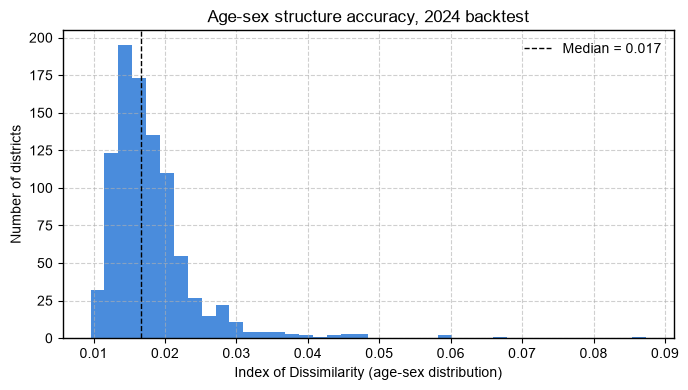

In [12]:
# Index of Dissimilarity (Rowland, 2003; used throughout Wilson & Grossman, 2022)
# quantifies whether the age-sex STRUCTURE was forecast correctly, independent
# of whether the total population was: IoD = 0.5 * sum(|forecast_share_i - actual_share_i|)
# over age-sex groups i. E.g. IoD=0.05 means 5% of a district's population
# would need to move between age-sex groups to match the actual distribution.
# This complements the age-pyramid plot below with a single accuracy number.
actual_state_cols = state_cols['m'] + state_cols['f']
actual_base = pop_dist[pop_dist['year'] == LAST_YEAR].set_index('dist_id')

iod_values = {}
for did, vecs in predicted_vecs.items():
    if did not in actual_base.index:
        continue
    pred_vec = np.concatenate([vecs['m'], vecs['f']])
    act_vec = actual_base.loc[did, actual_state_cols].to_numpy(dtype=float)
    if pred_vec.sum() == 0 or act_vec.sum() == 0:
        continue
    pred_share = pred_vec / pred_vec.sum()
    act_share = act_vec / act_vec.sum()
    iod_values[did] = 0.5 * np.abs(pred_share - act_share).sum()

iod = pd.Series(iod_values)
print(f"Age-sex distribution accuracy (Index of Dissimilarity), n={len(iod)}:")
print(f"  Median IoD = {iod.median():.4f}   90th percentile IoD = {iod.quantile(.9):.4f}")
print(f"  (i.e. a typical district would need to reallocate {iod.median():.1%} of its "
      f"population across age-sex groups to match the actual {LAST_YEAR} distribution)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(iod, bins=40, color=series1, alpha=0.85)
ax.axvline(iod.median(), color='black', linewidth=1, linestyle='--', label=f'Median = {iod.median():.3f}')
ax.set_xlabel('Index of Dissimilarity (age-sex distribution)')
ax.set_ylabel('Number of districts')
ax.set_title(f'Age-sex structure accuracy, {LAST_YEAR} backtest')
ax.legend(frameon=False)
ax.grid(True)
plt.tight_layout()
plt.show()

Province-level rollup (n=77):
Hamilton-Perry CCR/CCD        MedAPE= 0.54%  MAPE= 1.46%  MedianPE(bias)=+0.38%  90th%APE= 2.70%


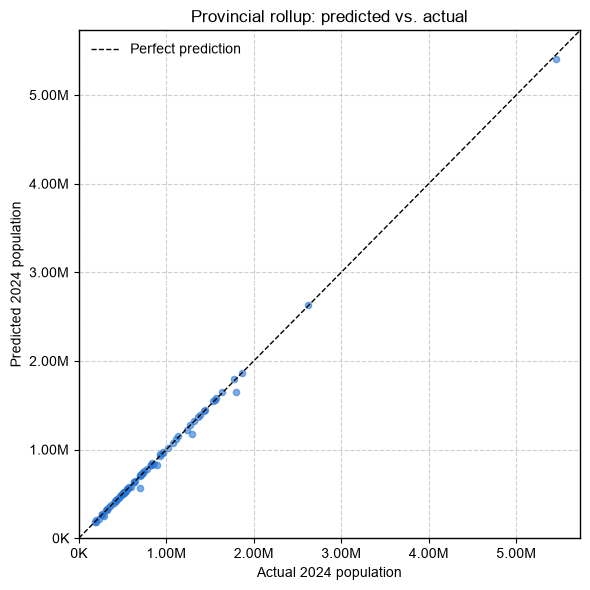


Worst 10 provinces by absolute % error:


,predicted,actual,error,pct_error
prov_id,,,,
63,5.655655e+05,698597,-133031.471126,-0.190427
58,2.495994e+05,288082,-38482.629882,-0.133582
57,1.175979e+06,1297657,-121677.537063,-0.093767
71,8.222504e+05,896351,-74100.636749,-0.082669
50,1.652937e+06,1799019,-146081.565834,-0.081201
85,1.817818e+05,192927,-11145.223763,-0.057769
23,2.185560e+05,226517,-7960.954334,-0.035145
70,8.400676e+05,864037,-23969.384859,-0.027741
74,5.752026e+05,590867,-15664.359271,-0.026511


In [13]:
# Roll the same district-level backtest predictions up to provincial level.
# This reuses the predictions already scored above (no retraining) — it just
# asks whether the district misses wash out once you aggregate to province,
# the same way the national total did.
backtest_prov = backtest.copy()
backtest_prov['prov_id'] = backtest_prov.index.map(dist_prov_map)
backtest_prov = backtest_prov.groupby('prov_id')[['predicted', 'actual']].sum()
backtest_prov['error'] = backtest_prov['predicted'] - backtest_prov['actual']
backtest_prov['pct_error'] = backtest_prov['error'] / backtest_prov['actual']

print(f"Province-level rollup (n={len(backtest_prov)}):")
report_metrics(backtest_prov['predicted'], backtest_prov['actual'], 'Hamilton-Perry CCR/CCD')

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(backtest_prov['actual'], backtest_prov['predicted'], s=20, alpha=0.6, color=series1)
lims = [0, max(backtest_prov['actual'].max(), backtest_prov['predicted'].max()) * 1.05]
ax.plot(lims, lims, color='black', linewidth=1, linestyle='--', label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(f'Actual {LAST_YEAR} population')
ax.set_ylabel(f'Predicted {LAST_YEAR} population')
ax.set_title('Provincial rollup: predicted vs. actual')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.2f}M' if x >= 1e6 else f'{x/1e3:.0f}K'))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.2f}M' if x >= 1e6 else f'{x/1e3:.0f}K'))
ax.legend(frameon=False)
ax.grid(True)
plt.tight_layout()
plt.show()

print('\nWorst 10 provinces by absolute % error:')
display(backtest_prov.reindex(backtest_prov['pct_error'].abs().sort_values(ascending=False).index).head(10))

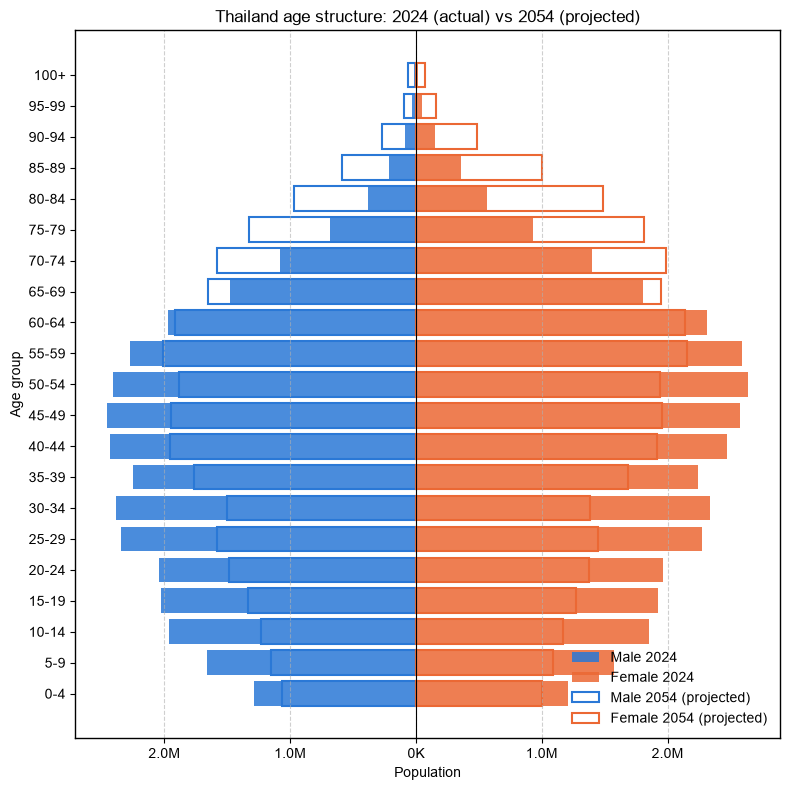

In [14]:
# Could I see the change of age-structure ---> construct as the age-pyramid graph

def age_pyramid_data(df, year, dist_id=None, prov_id=None):
    """Aggregate single-year age/sex columns into 5-year bins for one year
    (optionally filtered to one district or province; national total otherwise)."""
    d = df[df['year'] == year]
    if dist_id is not None:
        d = d[d['dist_id'] == dist_id]
    elif prov_id is not None:
        d = d[d['prov_id'] == prov_id]
    row = d[[c for c in d.columns if c.startswith(('m_yr', 'f_yr'))]].sum()

    labels, m_vals, f_vals = [], [], []
    for lo in range(0, MAX_SINGLE_AGE + 1, 5):
        labels.append(f'{lo}-{lo + 4}')
        m_vals.append(sum(row[f'm_yr{a}'] for a in range(lo, lo + 5)))
        f_vals.append(sum(row[f'f_yr{a}'] for a in range(lo, lo + 5)))
    labels.append('100+')
    m_vals.append(row['m_yr100p'])
    f_vals.append(row['f_yr100p'])
    return labels, np.array(m_vals), np.array(f_vals)


def plot_age_pyramid(df, year_base, year_compare, dist_id=None, prov_id=None, title=None):
    """Overlay two age pyramids: solid bars for year_base, outlined bars for
    year_compare, so the shift in age structure reads as the gap between them."""
    labels, m_base, f_base = age_pyramid_data(df, year_base, dist_id, prov_id)
    _, m_cmp, f_cmp = age_pyramid_data(df, year_compare, dist_id, prov_id)

    male_color, female_color = '#2a78d6', '#eb6834'  # validated categorical slots 1 & 2
    y = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.barh(y, -m_base, color=male_color, alpha=0.85, label=f'Male {year_base}')
    ax.barh(y, f_base, color=female_color, alpha=0.85, label=f'Female {year_base}')
    ax.barh(y, -m_cmp, facecolor='none', edgecolor=male_color, linewidth=1.5, label=f'Male {year_compare} (projected)')
    ax.barh(y, f_cmp, facecolor='none', edgecolor=female_color, linewidth=1.5, label=f'Female {year_compare} (projected)')

    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_xlabel('Population')
    ax.set_ylabel('Age group')
    ax.set_title(title or f'Age structure: {year_base} vs {year_compare} (projected)')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(
        lambda x, _: f'{abs(x) / 1e6:.1f}M' if abs(x) >= 1e6 else f'{abs(x) / 1e3:.0f}K'
    ))
    ax.axvline(0, color='black', linewidth=0.8)
    ax.legend(loc='lower right', frameon=False)
    ax.grid(True, axis='x')
    plt.tight_layout()
    plt.show()

# National age structure: latest actual year vs. the end of the projection horizon
plot_age_pyramid(pop_dist_proj, LAST_YEAR, LAST_YEAR + HORIZON,
                  title=f'Thailand age structure: {LAST_YEAR} (actual) vs {LAST_YEAR + HORIZON} (projected)')

In [15]:
# Okay let's move to workforce to population as well
#
# i have the data of workforce in each level and also the change trend
# so if we start with 2024 data of workforce as well (might be tailored with doctor and nurse)
# 1. i want to see the changing in outcome of Gini (the calculation might be in other notebook)
#    in case of number of workforce is not change (reflecting that input = output)
#
# and if i want to improve gini, what is the priorities in case
# 1. number of workforce is not change ... but their could shift among the province
# 2. number of workforce change with rate (might be + or -) but the shifting among the province in inhibit
# 3. condition 1 + 2

In [16]:
# --- Workforce-population equity (Gini) scenarios, province level ---
# Reuses analyse.gini() (the same population-weighted Lorenz-curve Gini already
# used in hrh.ipynb / Table 6) and the workforce data it already produced:
# Table 3 (province-level HRH totals by year & cadre, public sector) for the
# 2024 baseline. We combine these with our own province-level population
# PROJECTION (rolled up from pop_dist_proj) instead of historical population,
# so Gini can be tracked forward under different workforce policies.
HRH_CADRES = ['doctor', 'nurse-prof']  # tailored to doctor & nurse per the request
BASE_YEAR = LAST_YEAR  # 2024, jump-off year for both the population and workforce projections

# Province name <-> prov_id crosswalk, sourced from the same hosp registry the
# HRH tables were already built from (so it matches Table 3's 'prov' exactly).
hosp_xwalk = pd.read_csv('output/clean/hosp_cleaned.csv', usecols=['prov_id', 'prov']).drop_duplicates()
hosp_xwalk['prov_id'] = hosp_xwalk['prov_id'].astype(int)

hrh_table1a = pd.read_csv('output/analyse/hrh/Table 1A Total Numbers of Physician and Specilist.csv')
hrh_table3 = pd.read_csv('output/analyse/hrh/Table 3 Density in provincial level.csv')

workforce_base = (
    hrh_table3[(hrh_table3['year'] == BASE_YEAR) & (hrh_table3['hrh'].isin(HRH_CADRES))]
    .merge(hosp_xwalk, on='prov', how='left')[['prov_id', 'hrh', 'total']]
)
assert workforce_base['prov_id'].isna().sum() == 0, "province name did not match the hosp crosswalk"

# For reference only: the historical trend, as median (not mean -- the mean is
# skewed by 2015->2016 reporting-coverage expansion) year-over-year change in
# public-sector headcount, people/year.
t1a = hrh_table1a[hrh_table1a['hrh'].isin(HRH_CADRES)].sort_values(['hrh', 'year']).copy()
t1a['public_diff'] = t1a.groupby('hrh')['total_public'].diff()
net_change_pyear_trend = t1a.groupby('hrh')['public_diff'].median()
print("Historical trend (median people/year, 2015-2024) -- for reference:")
display(net_change_pyear_trend)

# --- Net change assumption actually used below: edit these directly to test ---
# --- your own production/attrition scenario, in people/year (net, +/-).     ---
net_change_pyear = pd.Series({
    'doctor': 1000,
    'nurse-prof': 1000,
})

# Our own province-level population projection (roll up the district projection built above)
pop_prov_proj = pop_dist_proj.groupby(['prov_id', 'year'], as_index=False)['pop'].sum()

print(f"\n{BASE_YEAR} public-sector workforce baseline:")
display(workforce_base.groupby('hrh')['total'].sum())
print("\nNet change assumption used in the scenarios below (people/year):")
display(net_change_pyear)

Historical trend (median people/year, 2015-2024) -- for reference:


hrh
doctor        2166.0
nurse-prof    1972.0
Name: public_diff, dtype: float64


2024 public-sector workforce baseline:


hrh
doctor         32465.0
nurse-prof    149422.0
Name: total, dtype: float64


Net change assumption used in the scenarios below (people/year):


doctor        1000
nurse-prof    1000
dtype: int64

In [17]:
# Redesigned scenario mechanics per feedback: the previous "redistribute" mode
# (instant perfect reallocation every year) was unrealistically ideal, and
# "grow" spread new headcount to preserve existing (unequal) shares rather than
# targeting need. This version separates two independent, realistic policy
# levers, applied year-by-year with state carried forward from the real 2024
# starting point:
#
#   Lever A -- bounded reallocation of EXISTING staff: at most
#   REDISTRIBUTION_CAP people/year physically move between provinces (e.g.
#   transfers/rotations), proportionally closing each province's gap to the
#   population-proportional ideal. This replaces the old instant-equalization
#   assumption with "movable just N people/year from high density to low
#   density" -- a gradual, budget-limited convergence, not a jump to Gini=0.
#
#   Lever B -- targeted placement of NEW workforce: the net_change_pyear people
#   entering (or leaving) the workforce each year are NOT existing staff being
#   moved, so "shifting inhibited" doesn't apply to them -- they can be placed
#   wherever need is greatest (e.g. compulsory placement of new graduates).
#   Two strategies, per the request:
#     'waterfall' -- fill the lowest-density province(s) up to the next
#        density tier first, cascading upward (spend the budget on whoever is
#        worst off until they're no longer the worst off, then move on).
#     'scarcity'  -- split the new positions proportional to each province's
#        absolute gap below the ideal target (bigger shortfall -> bigger share).
#
# The four scenarios requested become: No change (neither lever), Redistribute
# only (Lever A alone), Grow only (Lever B alone, shifting inhibited = Lever A
# off), and Grow + redistribute (Lever A + B together -- "summation of the two
# mechanisms").
REDISTRIBUTION_CAP = 300  # illustrative cap: staff transfers/rotations per year

def bounded_redistribute(current, pop_y, cap):
    """Lever A: move up to `cap` people this year from over- toward
    under-supplied provinces, proportionally closing the gap to the
    population-proportional ideal target."""
    target = current.sum() * (pop_y / pop_y.sum())
    gap = target - current
    shortfall = gap[gap > 0].sum()
    if shortfall <= 0:
        return current
    scale = min(cap, shortfall) / shortfall
    return current + gap * scale


def waterfall_place(current, pop_y, increment, tol=1e-6):
    """Lever B, strategy 1: water-filling -- raise the lowest-density
    province(s) up to the next density tier, cascading upward until the new
    headcount is used up."""
    current = current.astype(float).copy()
    if increment <= 0:  # net loss: scale down proportional to current allocation
        return current * (1 + increment / current.sum())
    remaining = float(increment)
    for _ in range(len(pop_y) + 5):
        if remaining <= tol:
            break
        density = current / pop_y
        min_d = density.min()
        at_min = density <= min_d + tol
        above = density[~at_min]
        if above.empty:  # already perfectly level: spread the rest by population
            current += remaining * (pop_y / pop_y.sum())
            break
        step = min(remaining, ((above.min() - min_d) * pop_y[at_min]).sum())
        current[at_min] += step * (pop_y[at_min] / pop_y[at_min].sum())
        remaining -= step
    return current


def scarcity_place(current, pop_y, increment):
    """Lever B, strategy 2: split new headcount proportional to each
    province's absolute shortfall below the population-proportional ideal."""
    if increment < 0:  # net loss: scale down proportional to current allocation
        return current * (1 + increment / current.sum())
    target = current.sum() * (pop_y / pop_y.sum())
    gap = np.maximum(target - current, 0)
    alloc = increment * (gap / gap.sum()) if gap.sum() > 0 else increment * (pop_y / pop_y.sum())
    return current + alloc


def gini_trend(pop_prov_proj, workforce_2024, base_year, redistribution_cap=0, placement=None, net_change_pyear=0.0):
    """placement: None (Lever B off) | 'waterfall' | 'scarcity'."""
    current = workforce_2024.set_index('prov_id')['total'].astype(float)
    rows = []
    for year in sorted(pop_prov_proj['year'].unique()):
        pop_y = pop_prov_proj.loc[pop_prov_proj['year'] == year].set_index('prov_id')['pop']
        common = current.index.intersection(pop_y.index)
        current, pop_y = current.loc[common], pop_y.loc[common]

        if year > base_year:
            if placement == 'waterfall' and net_change_pyear != 0:
                current = waterfall_place(current, pop_y, net_change_pyear)
            elif placement == 'scarcity' and net_change_pyear != 0:
                current = scarcity_place(current, pop_y, net_change_pyear)
            if redistribution_cap > 0:
                current = bounded_redistribute(current, pop_y, redistribution_cap)

        d = pd.DataFrame({'total': current, 'pop': pop_y})
        rows.append({'year': year, 'gini': analyse.gini(d, 'total', 'pop'), 'total_workforce': d['total'].sum()})
    return pd.DataFrame(rows)

# Scenario definitions: (label, redistribution_cap, placement)
SCENARIOS = [
    ('No change', 0, None),
    ('Redistribute only (bounded)', REDISTRIBUTION_CAP, None),
    ('Grow only - waterfall', 0, 'waterfall'),
    ('Grow only - scarcity', 0, 'scarcity'),
    ('Grow + redistribute - waterfall', REDISTRIBUTION_CAP, 'waterfall'),
    ('Grow + redistribute - scarcity', REDISTRIBUTION_CAP, 'scarcity'),
]

gini_results = {}
for hrh in HRH_CADRES:
    wf0 = workforce_base[workforce_base['hrh'] == hrh][['prov_id', 'total']]
    r = net_change_pyear[hrh]
    gini_results[hrh] = {
        label: gini_trend(pop_prov_proj, wf0, BASE_YEAR, cap, placement, r)
        for label, cap, placement in SCENARIOS
    }

for hrh in HRH_CADRES:
    print(f"=== {hrh} (net change trend {net_change_pyear[hrh]:+,.0f} people/yr, "
          f"redistribution cap {REDISTRIBUTION_CAP}/yr) ===")
    for label, df in gini_results[hrh].items():
        print(f"  {label:34s}  Gini {BASE_YEAR}={df.iloc[0]['gini']:.4f}  ->  "
              f"{df['year'].max()}={df.iloc[-1]['gini']:.4f}")
    print()

=== doctor (net change trend +1,000 people/yr, redistribution cap 300/yr) ===
  No change                           Gini 2024=0.2524  ->  2054=0.2650
  Redistribute only (bounded)         Gini 2024=0.2524  ->  2054=-0.0000
  Grow only - waterfall               Gini 2024=0.2524  ->  2054=0.0244
  Grow only - scarcity                Gini 2024=0.2524  ->  2054=0.0260
  Grow + redistribute - waterfall     Gini 2024=0.2524  ->  2054=-0.0000
  Grow + redistribute - scarcity      Gini 2024=0.2524  ->  2054=0.0011

=== nurse-prof (net change trend +1,000 people/yr, redistribution cap 300/yr) ===
  No change                           Gini 2024=0.1575  ->  2054=0.1828
  Redistribute only (bounded)         Gini 2024=0.1575  ->  2054=0.1055
  Grow only - waterfall               Gini 2024=0.1575  ->  2054=0.0743
  Grow only - scarcity                Gini 2024=0.1575  ->  2054=0.0912
  Grow + redistribute - waterfall     Gini 2024=0.1575  ->  2054=0.0216
  Grow + redistribute - scarcity      Gini 20

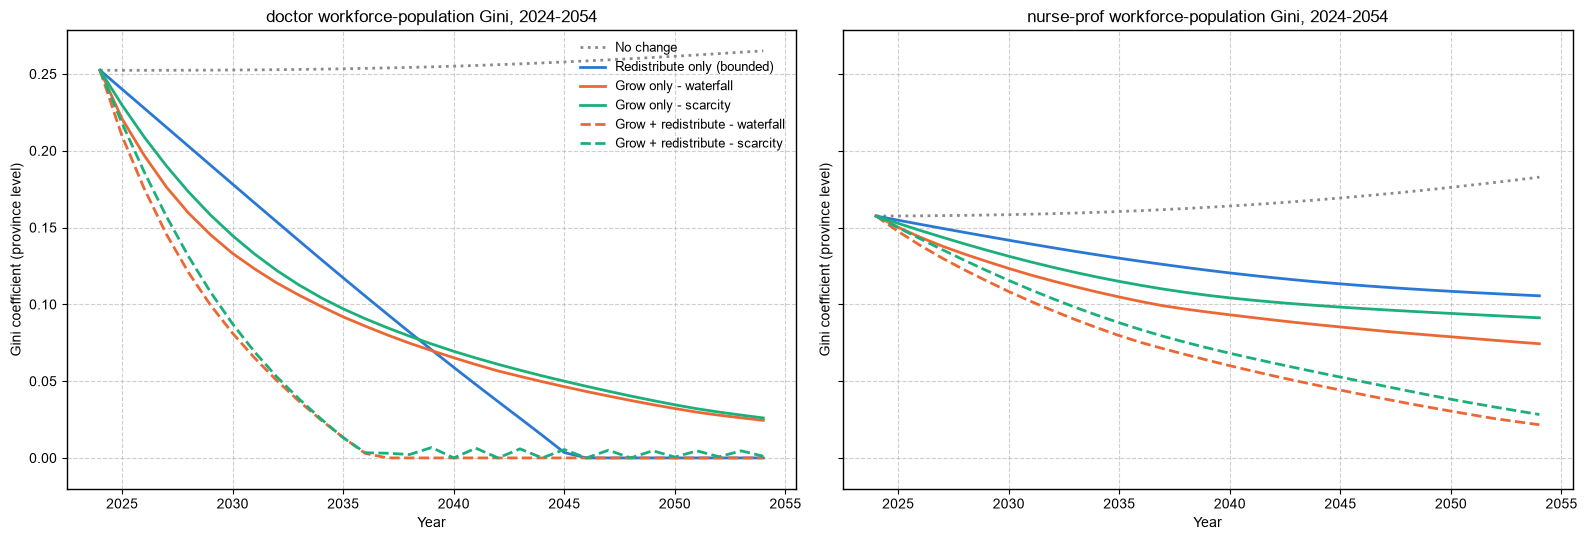

All scenarios start at the real, observed 2024 Gini (0.2524 doctor / 0.1575 nurse-prof) and only
diverge from 2025, once a policy is simulated. Redistribution (Lever A) is now capped at 300/yr -- a realistic staff-transfer budget -- not an instant jump to equality.

doctor: 2054 Gini -- No change 0.265 | Redistribute-only -0.000 | Grow-waterfall 0.024 | Grow-scarcity 0.026 | Combined-waterfall -0.000 | Combined-scarcity 0.001
nurse-prof: 2054 Gini -- No change 0.183 | Redistribute-only 0.106 | Grow-waterfall 0.074 | Grow-scarcity 0.091 | Combined-waterfall 0.022 | Combined-scarcity 0.028

Priority answer, updated: with a realistic transfer cap, moving EXISTING staff alone barely dents
inequality for nurse-prof (workforce ~149K, cap only 300/yr is a rounding error) and helps only
modestly for doctor (smaller base, so the same cap is a bigger relative lever). What actually closes
the gap fastest is targeting NEW workforce at underserved provinces (Lever B) -- because the growth
trend (th

In [18]:
# Plot the Gini trend under all six scenarios, one panel per cadre.
# Color carries "which mechanism(s)" (gray=none, blue=redistribute-existing-only,
# orange=waterfall placement, aqua=scarcity placement); solid vs dashed carries
# "plus bounded redistribution of existing staff or not" -- so the effect of
# adding Lever A reads as the gap between a solid and its dashed twin.
palette = {
    'No change': '#8a8a86',
    'Redistribute only (bounded)': '#2a78d6',
    'Grow only - waterfall': '#eb6834', 'Grow + redistribute - waterfall': '#eb6834',
    'Grow only - scarcity': '#1baf7a', 'Grow + redistribute - scarcity': '#1baf7a',
}
linestyle = {
    'No change': ':',
    'Redistribute only (bounded)': '-',
    'Grow only - waterfall': '-', 'Grow + redistribute - waterfall': '--',
    'Grow only - scarcity': '-', 'Grow + redistribute - scarcity': '--',
}

fig, axes = plt.subplots(1, len(HRH_CADRES), figsize=(8 * len(HRH_CADRES), 5.5), sharey=True)
for ax, hrh in zip(np.atleast_1d(axes), HRH_CADRES):
    for label, df in gini_results[hrh].items():
        ax.plot(df['year'], df['gini'], label=label, color=palette[label], linestyle=linestyle[label], linewidth=2)
    ax.set_title(f'{hrh} workforce-population Gini, {BASE_YEAR}-{pop_prov_proj["year"].max()}')
    ax.set_xlabel('Year')
    ax.set_ylabel('Gini coefficient (province level)')
    ax.set_ylim(bottom=-0.02)
    ax.grid(True)
axes_list = np.atleast_1d(axes)
axes_list[0].legend(frameon=False, loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"All scenarios start at the real, observed 2024 Gini (0.2524 doctor / 0.1575 nurse-prof) and only")
print(f"diverge from 2025, once a policy is simulated. Redistribution (Lever A) is now capped at "
      f"{REDISTRIBUTION_CAP}/yr -- a realistic staff-transfer budget -- not an instant jump to equality.\n")

for hrh in HRH_CADRES:
    g2054 = {label: df.iloc[-1]['gini'] for label, df in gini_results[hrh].items()}
    print(f"{hrh}: 2054 Gini -- No change {g2054['No change']:.3f} | "
          f"Redistribute-only {g2054['Redistribute only (bounded)']:.3f} | "
          f"Grow-waterfall {g2054['Grow only - waterfall']:.3f} | "
          f"Grow-scarcity {g2054['Grow only - scarcity']:.3f} | "
          f"Combined-waterfall {g2054['Grow + redistribute - waterfall']:.3f} | "
          f"Combined-scarcity {g2054['Grow + redistribute - scarcity']:.3f}")

print("\nPriority answer, updated: with a realistic transfer cap, moving EXISTING staff alone barely dents")
print(f"inequality for nurse-prof (workforce ~149K, cap only {REDISTRIBUTION_CAP}/yr is a rounding error) and helps only")
print("modestly for doctor (smaller base, so the same cap is a bigger relative lever). What actually closes")
print("the gap fastest is targeting NEW workforce at underserved provinces (Lever B) -- because the growth")
print("trend (thousands/year) dwarfs the transfer cap (hundreds/year) for both cadres here. Waterfall")
print("(fill the worst-off first) converges faster than scarcity-weighting (spreads growth proportional to")
print("gap size, so small underserved provinces wait longer even though they could be fixed cheaply).")
print("Combining both levers always beats either alone, but the marginal gain from ALSO moving existing")
print("staff is small next to targeted placement of new staff, given how small the cap is relative to growth.\n")

print("This conclusion is sensitive to REDISTRIBUTION_CAP: raise it (a bigger annual transfer program) and")
print("Lever A's contribution grows; at cap -> total workforce, 'Redistribute only' converges toward the old")
print("instant-equalization ceiling. Try re-running with a larger cap to see where the crossover is.")

In [34]:
# Turn "Redistribute only" from an aggregate Gini number into an actual plan:
# which province should send staff to which province, and how many. bounded_redistribute()
# closes every province's gap a little in proportion (needed for a smooth Gini curve), but a
# real transfer program moves whole people between two named places -- so this greedy match
# pairs the biggest current surplus with the biggest current shortfall, moves as much as the
# annual cap (or the smaller side of the gap) allows, then repeats with what's left of the cap.
def redistribution_plan(current, pop_y, cap):
    target = current.sum() * (pop_y / pop_y.sum())
    gap = (target - current).copy()  # positive = needs staff (recipient), negative = surplus (donor)
    remaining = cap
    plan = []
    for _ in range(len(gap) * 2):
        if remaining <= 1e-6:
            break
        donor, recipient = gap.idxmin(), gap.idxmax()
        if gap[donor] >= -1e-6 or gap[recipient] <= 1e-6:
            break  # no province left with a real surplus or a real shortfall
        amount = min(remaining, -gap[donor], gap[recipient])
        if amount <= 1e-6:
            break
        plan.append({'from_prov_id': donor, 'to_prov_id': recipient, 'n_people': amount})
        gap[donor] += amount
        gap[recipient] -= amount
        remaining -= amount
    return pd.DataFrame(plan)

def named_plan(plan):
    return (plan
            .merge(hosp_xwalk.rename(columns={'prov_id': 'from_prov_id', 'prov': 'from_prov'}), on='from_prov_id')
            .merge(hosp_xwalk.rename(columns={'prov_id': 'to_prov_id', 'prov': 'to_prov'}), on='to_prov_id')
            [['from_prov', 'to_prov', 'n_people']])

PLAN_YEARS = 30  # how many years of the plan to lay out

for hrh in HRH_CADRES:
    wf = workforce_base[workforce_base['hrh'] == hrh].set_index('prov_id')['total'].astype(float)
    current = wf.copy()
    all_plans = []
    for year in range(BASE_YEAR + 1, BASE_YEAR + 1 + PLAN_YEARS):
        pop_y = pop_prov_proj.loc[pop_prov_proj['year'] == year].set_index('prov_id')['pop']
        common = current.index.intersection(pop_y.index)
        current, pop_y = current.loc[common], pop_y.loc[common]
        year_plan = redistribution_plan(current, pop_y, REDISTRIBUTION_CAP)
        year_plan['year'] = year
        all_plans.append(year_plan)
        current = bounded_redistribute(current, pop_y, REDISTRIBUTION_CAP)
    all_plans = pd.concat(all_plans, ignore_index=True)

    print(f"=== {hrh}: redistribution plan, {BASE_YEAR + 1} first ({REDISTRIBUTION_CAP}/yr cap) ===")
    first_year = named_plan(all_plans[all_plans['year'] == BASE_YEAR + 1])
    display(first_year.round(0))

    print(f"Cumulative {BASE_YEAR + 1}-{BASE_YEAR + PLAN_YEARS} totals by province pair:")
    cumulative = named_plan(all_plans).groupby(['from_prov', 'to_prov'])['n_people'].sum().sort_values(ascending=False)
    display(cumulative.round(0))
    print()

=== doctor: redistribution plan, 2025 first (300/yr cap) ===


,from_prov,to_prov,n_people
0,กรุงเทพมหานคร,ศรีสะเกษ,300.0


Cumulative 2025-2054 totals by province pair:


from_prov      to_prov        
กรุงเทพมหานคร  สมุทรปราการ        2945.0
               ศรีสะเกษ           1950.0
               ระยอง               411.0
               ชลบุรี              348.0
               ปทุมธานี            173.0
                                   ...  
กำแพงเพชร      ประจวบคีรีขันธ์       0.0
อำนาจเจริญ     สมุทรปราการ           0.0
เชียงราย       สระบุรี               0.0
กำแพงเพชร      ภูเก็ต                0.0
สมุทรสงคราม    ประจวบคีรีขันธ์       0.0
Name: n_people, Length: 441, dtype: float64


=== nurse-prof: redistribution plan, 2025 first (300/yr cap) ===


,from_prov,to_prov,n_people
0,กรุงเทพมหานคร,สมุทรปราการ,300


Cumulative 2025-2054 totals by province pair:


from_prov      to_prov    
กรุงเทพมหานคร  สมุทรปราการ    9000
Name: n_people, dtype: int64

In [35]:
display(all_plans)

,from_prov_id,to_prov_id,n_people,year
0,10,11,300,2025
1,10,11,300,2026
2,10,11,300,2027
3,10,11,300,2028
4,10,11,300,2029
5,10,11,300,2030
6,10,11,300,2031
7,10,11,300,2032
8,10,11,300,2033
9,10,11,300,2034
